#**Librerias y funciones matematicas**

In [1]:
import math
import random
import numpy as np
import matplotlib.pyplot as plt

v_pi = math.pi

def F1_xy(x, y):
    f = x**2 + 2*y**2 - 0.3*math.sin(3*v_pi*x) - 0.4*math.cos(4*v_pi*y) + 0.4
    return f

def F2_xyz(x, y, z):
    termino1 = ((x**2 + y**2)**0.25) * (1 + (math.sin(50 * (x**2 + y**2)**0.1))**2)
    termino2 = ((y**2 + z**2)**0.25) * (1 + (math.sin(50 * (y**2 + z**2)**0.1))**2)
    termino3 = ((x**2 + z**2)**0.25) * (1 + (math.sin(50 * (x**2 + z**2)**0.1))**2)
    return termino1 + termino2 + termino3



#**Desarrollo: Algoritmo Genetico Simple**


##**Eleccion de parametros para el AGS**

In [2]:
def configurar_sga(fase):
    print("CONFIGURACION DEL ALGORITMO GENETICO SIMPLE (SGA) ")
    config = {"fase": fase}

    if fase == "2.1":
        print("\nConfiguracion Fase 2.1")
        config['f_optimizar'] = input("Seleccion de la funcion a optimizar (F1 o F2) [F1 por defecto]: ").strip().upper() or "F1"
        config['t_optimizacion'] = input("Tipo de tarea (MAX o MIN) [MAX por defecto]: ").strip().upper() or "MAX"
        config['n_poblacion'] = int(input("Tamano de la poblacion (n) [100 por defecto]: ").strip() or 100)
        config['epoch_max'] = int(input("Cantidad maxima de generaciones [50 por defecto, max 100]: ").strip() or 50)

        # Validacion del limite maximo de generaciones
        if config['epoch_max'] > 100:
            config['epoch_max'] = 100
            print("Aviso: Se ajusto la cantidad de generaciones al maximo permitido (100).")

        config['p_cruce'] = float(input("Probabilidad de cruce (Pc) en decimal [0.80 por defecto]: ").strip() or 0.80)
        config['p_mutacion'] = float(input("Probabilidad de mutacion (Pm) en decimal [0.01 por defecto]: ").strip() or 0.01)
        config['corridas'] = int(input("Numero de corridas automaticas a ejecutar [5 por defecto]: ").strip() or 5)

        print("\nNOTA: Para la fase 2.1, el numero de bits del cromosoma sera limitado obligatoriamente")
        print("por el ejercicio, el cual evaluara presiciones de 2, 3 y 4 digitos decimales.")

    elif fase == "2.2":
        print("\nConfiguracion Fase 2.2")
        config['f_optimizar'] = "F2"
        config['t_optimizacion'] = input("Tipo de tarea (MAX o MIN) [MIN por defecto]: ").strip().upper() or "MIN"

        print("\nDefinicion de longitud cromosomica (bits independientes por variable):")
        config['bits'] = {}
        config['bits']['x'] = int(input("Numero de bits para la variable X: ").strip())
        config['bits']['y'] = int(input("Numero de bits para la variable Y: ").strip())

        z_input = input("Numero de bits para la variable Z: ").strip()
        if z_input:
            config['bits']['z'] = int(z_input)

        config['corridas'] = int(input("Numero de corridas automaticas a ejecutar [1 por defecto]: ").strip() or 1)

        print("\nNOTA: Para la fase 2.2 se ejecutaran pruebas de variacion (N por arriba y N por abajo)")
        print("sobre los siguientes valores base por defecto:")
        print("- Probabilidad de Cruce (Pc): 0.80")
        print("- Probabilidad de Mutacion (Pm): 0.01")
        print("- Tamano Poblacion (n): 100")
        print("- Numero de Generaciones: 50")

        config['valores_base'] = {
            'p_cruce': 0.80,
            'p_mutacion': 0.01,
            'n_poblacion': 100,
            'epoch_max': 50
        }

    else:
        print("\nError: Fase no reconocida. Por favor ejecute la configuracion nuevamente.")
        return None

    print("\nConfiguracion completada exitosamente.")
    return config



##**1. Inicialización de la Poblacion**
    

In [3]:
def inicializar_poblacion(f_optimizar, precision_digitos, n):

    # Factor multiplicador (10^p)
    factor_10 = 10 ** precision_digitos

    # Calculo de bits
    if f_optimizar == "F1":
        # Rango de X y Y es [-10, 10], longitud = 20
        longitud_x = 10 - (-10)
        longitud_y = 10 - (-10)

        n_bits_cromosoma_x = math.ceil(math.log2(longitud_x * factor_10 + 1))
        n_bits_cromosoma_y = math.ceil(math.log2(longitud_y * factor_10 + 1))
        n_bits_cromosoma_z = 0

    elif f_optimizar == "F2":
        # Rango X [-5, 10] -> longitud = 15
        # Rango Y [-3, 9] -> longitud = 12
        # Rango Z [-1, 2.5] -> longitud = 3.5
        longitud_x = 10 - (-5)
        longitud_y = 9 - (-3)
        longitud_z = 2.5 - (-1)

        n_bits_cromosoma_x = math.ceil(math.log2(longitud_x * factor_10 + 1))
        n_bits_cromosoma_y = math.ceil(math.log2(longitud_y * factor_10 + 1))
        n_bits_cromosoma_z = math.ceil(math.log2(longitud_z * factor_10 + 1))


    # Calculamos la longitud total del cromosoma
    # Sumamos los bits de x, y, z (si es F1, z vale 0)
    longitud_total = n_bits_cromosoma_x + n_bits_cromosoma_y + n_bits_cromosoma_z

    poblacion = []

    # Generamos n cromosomas (individuos)
    for i in range(n):
        cromosoma = [random.randint(0, 1) for _ in range(longitud_total)]
        poblacion.append(cromosoma)

    # Retornamos la poblacion generada y la estructura de los bits
    # para que la fase de evaluación sepa como decodificarlos
    return poblacion, n_bits_cromosoma_x, n_bits_cromosoma_y, n_bits_cromosoma_z


##**2. Decodificacion y Escalado**

In [4]:
def extraer_genes(individuo, n_bits_x, n_bits_y, n_bits_z, f_optimizar):

    # Siempre extraemos x e y
    x_i = individuo[0 : n_bits_x]
    y_i = individuo[n_bits_x : n_bits_x + n_bits_y]

    if f_optimizar == "F2":
        # Extraemos z solo si es F2
        inicio_z = n_bits_x + n_bits_y
        z_i = individuo[inicio_z : inicio_z + n_bits_z]
        genes = [x_i, y_i, z_i]
    else:
        # Solo x e y para F1
        genes = [x_i, y_i]

    return genes

# Definimos la funcion que se encarga de hacer la conversion de binadio a decimal y el escalado lineal.
def decodificar_variable(cadena_bits, limite_inf, limite_sup):

    #Convertir bits a decimal
    cadena_binaria = "".join(map(str, cadena_bits))
    decimal = int(cadena_binaria, 2)

    m = len(cadena_bits)
    max_decimal = (2**m) - 1

    #Aplicar escalado lineal
    valor_real = limite_inf + decimal * ((limite_sup - limite_inf) / max_decimal)

    return valor_real


##**3. Calculo del Fitness**
    

In [5]:

# Al obtener el valor real (valor decimal escalado), tenemos que calcular el fitness segun la funcion seleccionada y el tipo de optimizacion (minimizar o maximizar).

def calcular_fitness(valores_reales, funcion_seleccionada, tipo_optimizacion):

    #Evaluamos el valor real en la funcion seleccionada
    valor_objetivo = 0 #inicializacion
    if funcion_seleccionada == "F1":
        valor_objetivo = F1_xy(valores_reales[0], valores_reales[1])
    elif funcion_seleccionada == "F2":
        valor_objetivo = F2_xyz(valores_reales[0], valores_reales[1], valores_reales[2])

    #MAXIMIZACION
    if tipo_optimizacion == "MAX":
        # Para maximizar mantenemos la proporción directa y asumimos que F1 y F2 en estos rangos son positivos
        fitness = valor_objetivo

        # Si el fitness da negativo lo forzamos a un número muy pequeño positivo para que la probabilidad de que sea seleccionado en la ruleta sea muy baja.
        if fitness <= 0:
            fitness = 0.0001
    #MINIZACION
    elif tipo_optimizacion == "MIN":
        # Para minimizar invertimos el valor por lo tanto los valores pequeños se vuelven grandes.
        # Añadimos 0.0001 para evitar división por cero. En el caso de que (valor_objetivo = 0), el fitness sera muy alto
        fitness = 1.0 / (valor_objetivo + 0.0001)

    return fitness, valor_objetivo


def evaluar_individuo_completo(individuo, bits_x, bits_y, bits_z, f_opt, t_opt):
    genes = extraer_genes(individuo, bits_x, bits_y, bits_z, f_opt)

    if f_opt == "F1":
        x_real = decodificar_variable(genes[0], -10, 10)
        y_real = decodificar_variable(genes[1], -10, 10)
        valores_reales = [x_real, y_real]
    else: # F2
        x_real = decodificar_variable(genes[0], -5, 10)
        y_real = decodificar_variable(genes[1], -3, 9)
        z_real = decodificar_variable(genes[2], -1, 2.5)
        valores_reales = [x_real, y_real, z_real]

    fitness_ind, valor_objetivo = calcular_fitness(valores_reales, f_opt, t_opt)
    return fitness_ind, valor_objetivo, valores_reales


def ejecutar_evolucion_f2(n_pob, epocas, prob_c, prob_m, n_bits_x, n_bits_y, n_bits_z, t_optimizacion):

    # Sumamos los bits de x, y, z
    longitud_total = n_bits_x + n_bits_y + n_bits_z

    poblacion = []

    # Generamos n cromosomas (individuos)
    for i in range(n):
        cromosoma = [random.randint(0, 1) for _ in range(longitud_total)]
        poblacion.append(cromosoma)

    historial_max = []
    mejor_valor_corrida = float('inf') if t_optimizacion == "MIN" else -float('inf')
    mejor_coordenadas_corrida = []

    for epoca in range(epocas):
        fitness_poblacion = []

        for individuo in poblacion:
            fit_ind, val_obj, coords_reales = evaluar_individuo_completo(
                individuo, n_bits_x, n_bits_y, n_bits_z, "F2", t_optimizacion
            )
            fitness_poblacion.append(fit_ind)

            if t_optimizacion == "MIN" and val_obj < mejor_valor_corrida:
                mejor_valor_corrida = val_obj
                mejor_coordenadas_corrida = coords_reales
            elif t_optimizacion == "MAX" and val_obj > mejor_valor_corrida:
                mejor_valor_corrida = val_obj
                mejor_coordenadas_corrida = coords_reales



        historial_max.append(max(fitness_poblacion))

        nueva_poblacion = []
        while len(nueva_poblacion) < n_pob:
            padre1 = seleccion_ruleta(poblacion, fitness_poblacion)
            padre2 = seleccion_ruleta(poblacion, fitness_poblacion)
            hijo1, hijo2 = cruce_un_punto(padre1, padre2, prob_c)
            mutacion(hijo1, prob_m)
            mutacion(hijo2, prob_m)

            # Si queda un hijo sobrante, lo matamos HEHEHE
            if len(nueva_poblacion) == n_pob - 1:
                fit_hijo1, _, _ = evaluar_individuo_completo(hijo1, n_bits_x, n_bits_y, n_bits_z, "F2", t_optimizacion)
                fit_hijo2, _, _ = evaluar_individuo_completo(hijo2, n_bits_x, n_bits_y, n_bits_z, "F2", t_optimizacion)
                if fit_hijo1 >= fit_hijo2:
                    nueva_poblacion.append(hijo1)
                else:
                    nueva_poblacion.append(hijo2)
            else:
                nueva_poblacion.append(hijo1)
                nueva_poblacion.append(hijo2)

        poblacion = nueva_poblacion

    return historial_max, mejor_valor_corrida, mejor_coordenadas_corrida


##**4. Seleccion de Padres**
    

In [6]:
#Metodo de seleccion para que los padres se puedan cruzar.
def seleccion_ruleta(poblacion, fitness_poblacion):

    # Calculamos el tamaño total de la ruleta
    suma_total_fitness = sum(fitness_poblacion)

    # Generamos el numero aleatorio entre 0 y la suma total del fitness
    r = random.uniform(0, suma_total_fitness)

    # Giramos la ruleta para ver donde cayo el numero random
    suma_acumulada = 0
    for i in range(len(poblacion)):
        suma_acumulada += fitness_poblacion[i]

        # En el momento en que la suma supera al numero random, ese individuo es el ganador
        if suma_acumulada >= r:
            return poblacion[i] # Devolvemos el padre ganador





##**5. Cruce**


In [7]:
#Debemos cruzar a los padres que seleccionamos utilizando la ruleta.
def cruce_un_punto(padre1, padre2, prob_cruce):
    # Generamos un random entre 0 y 1 para ver si ocurre el cruce
    if random.random() < prob_cruce:
        #Elegimos el punto de corte entre 1 y el penultimo bit
        punto_corte = random.randint(1, len(padre1) - 1)

        # Intercambiamos los genes
        hijo1 = padre1[:punto_corte] + padre2[punto_corte:]
        hijo2 = padre2[:punto_corte] + padre1[punto_corte:]
    else:
        # Si numero generado aleatoriamente es mayor a prob_cruce, los hijos son copias exactas
        hijo1 = padre1[:]
        hijo2 = padre2[:]

    return hijo1, hijo2


##**6. Mutacion**


In [8]:
#Aplicamos el factor de mutacion a los hijos
def mutacion(cromosoma, prob_mutacion):

    for i in range(len(cromosoma)):
        # Generamos un numero aleatorio entre 0 y 1 para este bit en específico
        r = random.random()
        if r < prob_mutacion:
            #Ocurre la mutacion e invertimos el bit
            cromosoma[i] = 1 - cromosoma[i]

    return cromosoma

#**7. Ejecucion fase 2**

##**7. Ejecucion fase 2.1**


FASE 2.1: OPTIMIZACION CON PARAMETROS FIJOS

CONFIGURACION DEL ALGORITMO GENETICO SIMPLE (SGA) 

Configuracion Fase 2.1
Seleccion de la funcion a optimizar (F1 o F2) [F1 por defecto]: 
Tipo de tarea (MAX o MIN) [MAX por defecto]: min
Tamano de la poblacion (n) [100 por defecto]: 
Cantidad maxima de generaciones [50 por defecto, max 100]: 
Probabilidad de cruce (Pc) en decimal [0.80 por defecto]: 
Probabilidad de mutacion (Pm) en decimal [0.01 por defecto]: 
Numero de corridas automaticas a ejecutar [5 por defecto]: 

NOTA: Para la fase 2.1, el numero de bits del cromosoma sera limitado obligatoriamente
por el ejercicio, el cual evaluara presiciones de 2, 3 y 4 digitos decimales.

Configuracion completada exitosamente.
 
EXPERIMENTO CON PRECISION: 2 DIGITOS DECIMALES


 Iniciando Corrida 1 de 5 

 Iniciando Corrida 2 de 5 

 Iniciando Corrida 3 de 5 

 Iniciando Corrida 4 de 5 

 Iniciando Corrida 5 de 5 


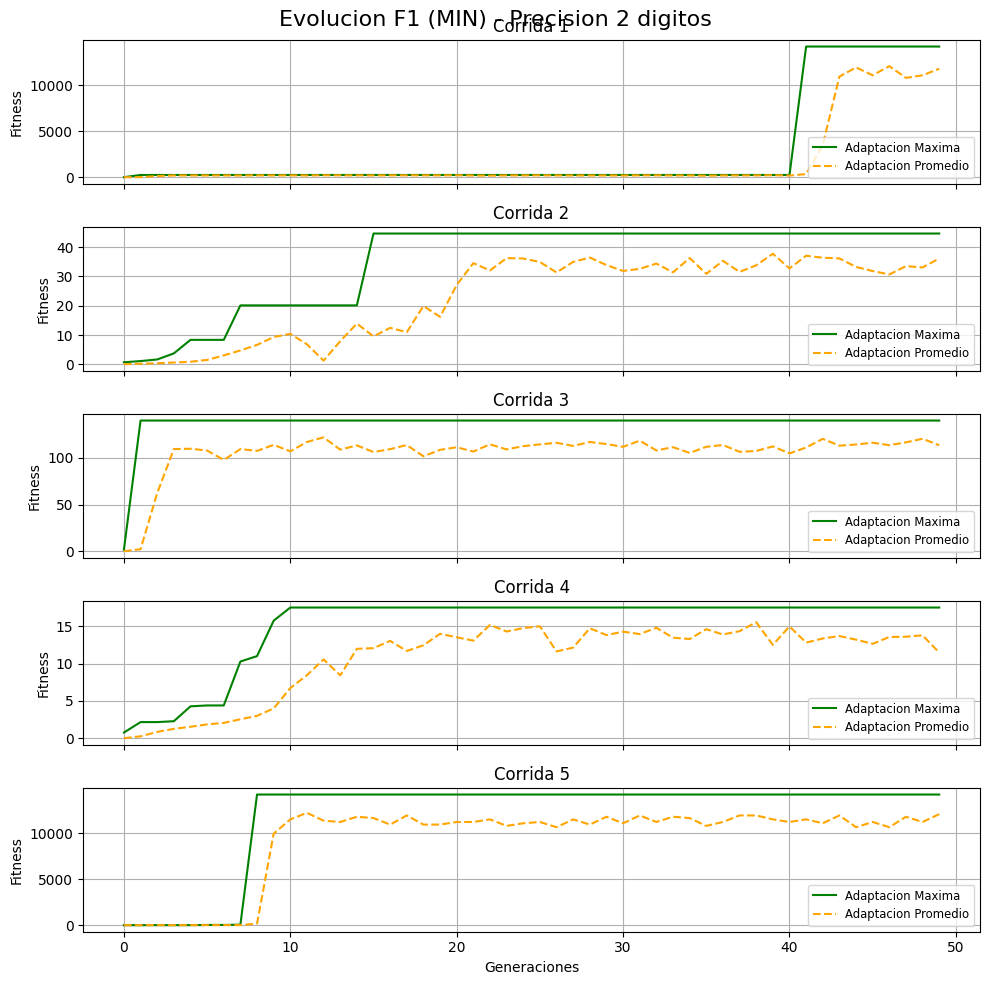

 
EXPERIMENTO CON PRECISION: 3 DIGITOS DECIMALES


 Iniciando Corrida 1 de 5 

 Iniciando Corrida 2 de 5 

 Iniciando Corrida 3 de 5 

 Iniciando Corrida 4 de 5 

 Iniciando Corrida 5 de 5 


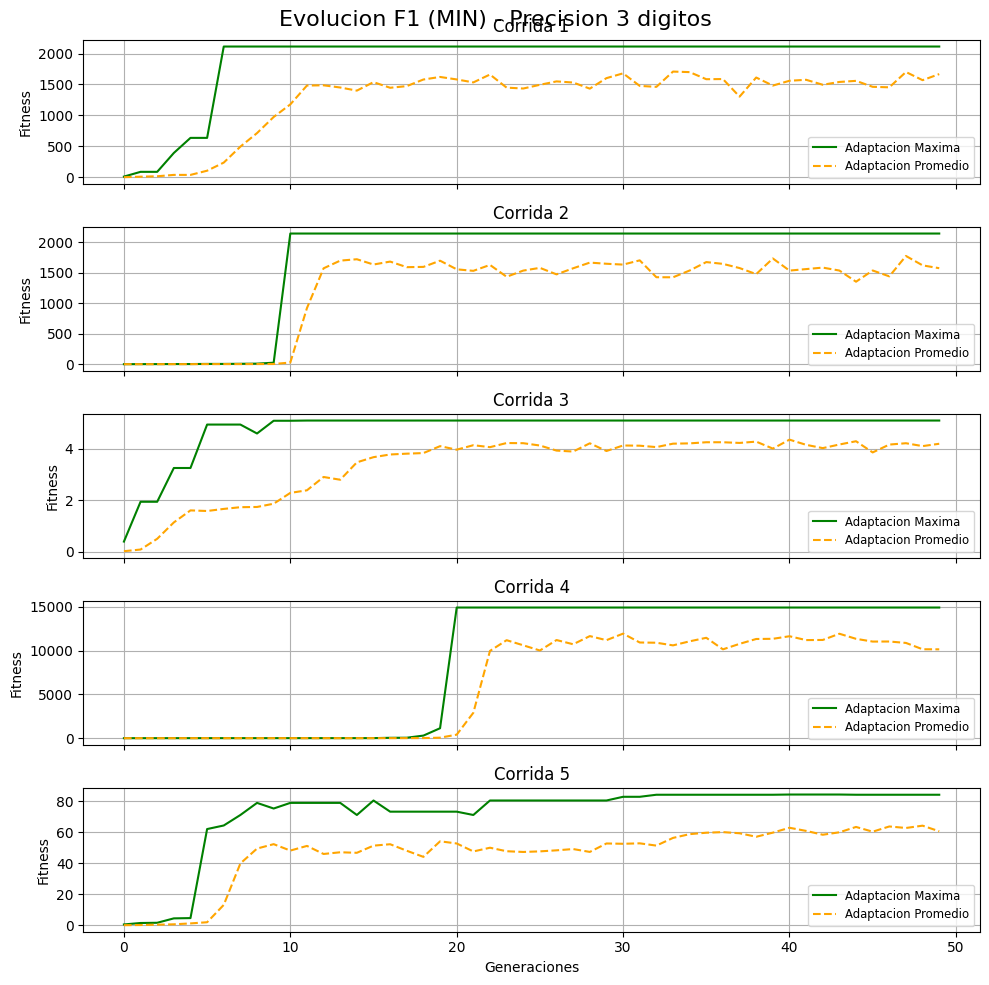

 
EXPERIMENTO CON PRECISION: 4 DIGITOS DECIMALES


 Iniciando Corrida 1 de 5 

 Iniciando Corrida 2 de 5 

 Iniciando Corrida 3 de 5 

 Iniciando Corrida 4 de 5 

 Iniciando Corrida 5 de 5 


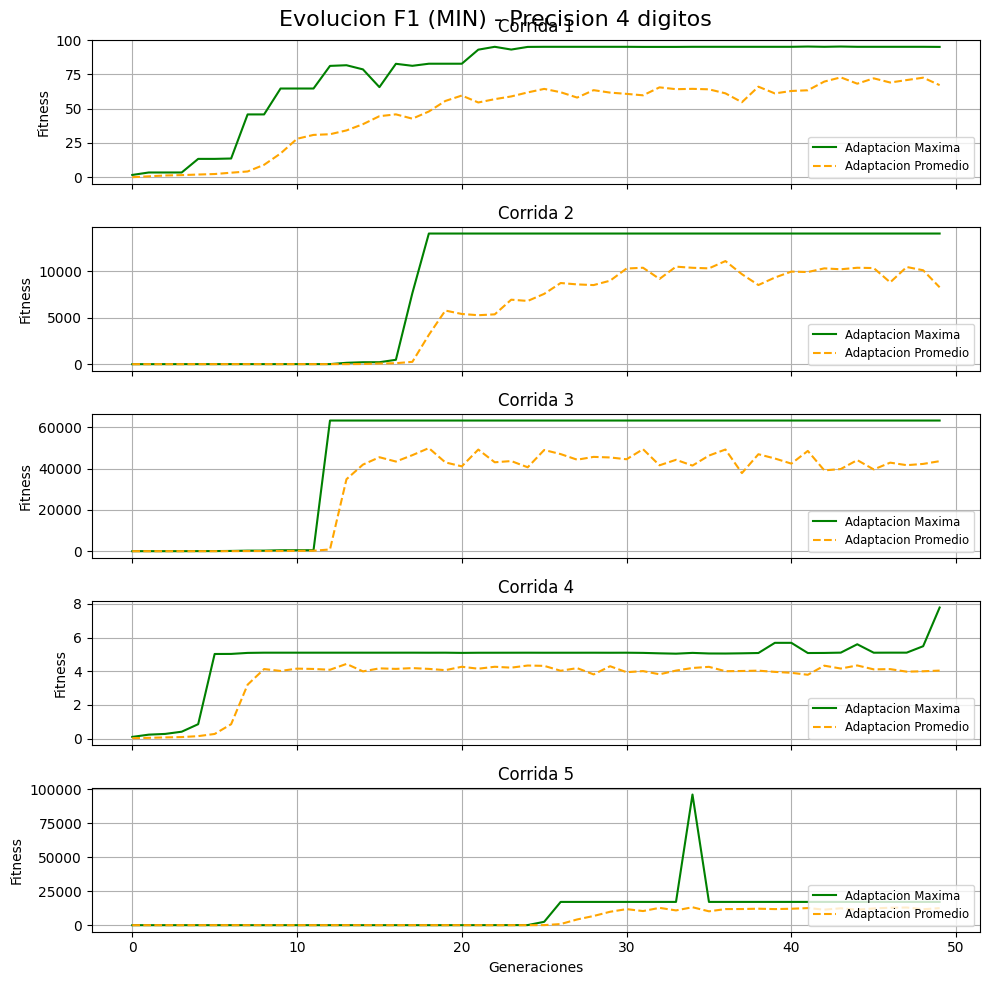

 
TABLA 1 MEJOR DE LA CORRIDA


Para Precision de 2 digitos:
Corrida 1 | Mejor F(x):   -0.05920 | Coordenadas: [X: -0.4738642, Y: -0.0146556]
Corrida 2 | Mejor F(x):   -0.21023 | Coordenadas: [X: 0.1612115, Y: -0.0439668]
Corrida 3 | Mejor F(x):   -0.06680 | Coordenadas: [X: -0.4640938, Y: -0.0048852]
Corrida 4 | Mejor F(x):   -0.26584 | Coordenadas: [X: 0.1319003, Y: 0.0048852]
Corrida 5 | Mejor F(x):   -0.18478 | Coordenadas: [X: 0.0830484, Y: 0.0244260]

Para Precision de 3 digitos:
Corrida 1 | Mejor F(x):   -0.06685 | Coordenadas: [X: -0.4715110, Y: -0.0015259]
Corrida 2 | Mejor F(x):   -0.11378 | Coordenadas: [X: 0.0729392, Y: 0.0466933]
Corrida 3 | Mejor F(x):   -0.27407 | Coordenadas: [X: 0.1541185, Y: -0.0015259]
Corrida 4 | Mejor F(x):   -0.25196 | Coordenadas: [X: 0.1748711, Y: 0.0222785]
Corrida 5 | Mejor F(x):   -0.26098 | Coordenadas: [X: 0.1535081, Y: 0.0198370]

Para Precision de 4 digitos:
Corrida 1 | Mejor F(x):   -0.27403 | Coordenadas: [X: 0.1568991, Y: 0.0015640]
Co

In [9]:
print("\nFASE 2.1: OPTIMIZACION CON PARAMETROS FIJOS\n")
fase_21 = "2.1"

parametros = configurar_sga(fase_21)

# Parametros fijos para la fase 2.1
precisiones_a_evaluar = [2, 3, 4]
n_corridas = parametros['corridas']
# Parametros variables para la fase 2.1
n = parametros['n_poblacion']
p_cruce = parametros['p_cruce']
p_mutacion = parametros['p_mutacion']
epoch_max = parametros['epoch_max']
f_optimizar = parametros['f_optimizar']
t_optimizacion = parametros['t_optimizacion']

# Estructura para guardar los mejores resultados finales y armar la Tabla 1 y 2
tabla_1_resultados = {}
tabla_2_resultados = {}

# BUCLE PRINCIPAL - Evalua las precisiones "precisiones_a_evaluar"
for precision_actual in precisiones_a_evaluar:
    print(f" \nEXPERIMENTO CON PRECISION: {precision_actual} DIGITOS DECIMALES\n")

    tabla_1_resultados[precision_actual] = []
    tabla_2_resultados[precision_actual] = []

    # Inicializacion de nuestra figura, se divide en "n_corridas" verticalmente para comparar cada evolucion
    fig, axs = plt.subplots(n_corridas, 1, figsize=(10, 10), sharex=True)
    fig.suptitle(f"Evolucion {f_optimizar} ({t_optimizacion}) - Precision {precision_actual} digitos", fontsize=16)

    for corrida in range(1, n_corridas + 1):
        print(f"\n Iniciando Corrida {corrida} de {n_corridas} ")

        # Inicializar poblacion nueva
        poblacion, n_bits_x, n_bits_y, n_bits_z = inicializar_poblacion(f_optimizar, precision_actual, n)

        # Listas para el grafico de esta corrida
        historial_max = []
        historial_promedio = []

        # Variables para rastrear al mejor de toda la corrida
        mejor_valor_corrida = float('inf') if t_optimizacion == "MIN" else -float('inf')
        mejor_coordenadas_corrida = []

        for epoca in range(epoch_max):

            # EVALUACION DE LA POBLACION ACTUAL
            fitness_poblacion = []

            mejor_fit_generacion = -float('inf')
            mejor_val_generacion = None
            mejor_coord_generacion = []

            for individuo in poblacion:
                fit_ind, val_obj, coords_reales = evaluar_individuo_completo(
                    individuo, n_bits_x, n_bits_y, n_bits_z, f_optimizar, t_optimizacion
                )
                fitness_poblacion.append(fit_ind)

                # Actualizamos el record historico de la corrida si encontramos uno mejor
                # Si minimizamos, buscamos el valor objetivo mas bajo. Si maximizamos, el mas alto.
                if t_optimizacion == "MIN" and val_obj < mejor_valor_corrida:
                    mejor_valor_corrida = val_obj
                    mejor_coordenadas_corrida = coords_reales
                elif t_optimizacion == "MAX" and val_obj > mejor_valor_corrida:
                    mejor_valor_corrida = val_obj
                    mejor_coordenadas_corrida = coords_reales


                if fit_ind > mejor_fit_generacion:
                    mejor_fit_generacion = fit_ind
                    mejor_val_generacion = val_obj
                    mejor_coord_generacion = coords_reales

            # Recoleccion de datos para los graficos
            max_gen = max(fitness_poblacion)
            promedio_gen = sum(fitness_poblacion) / len(fitness_poblacion)

            historial_max.append(max_gen)
            historial_promedio.append(promedio_gen)

            if epoca == epoch_max - 1:
                tabla_2_resultados[precision_actual].append({
                    "corrida": corrida,
                    "mejor_valor": mejor_val_generacion,
                    "coordenadas": mejor_coord_generacion
                })
            # SELECCION Y REPRODUCCION SIN ELITISMO
            nueva_poblacion = []

            while len(nueva_poblacion) < n:
                # Seleccion por Ruleta
                padre1 = seleccion_ruleta(poblacion, fitness_poblacion)
                padre2 = seleccion_ruleta(poblacion, fitness_poblacion)

                # Cruce de un punto
                hijo1, hijo2 = cruce_un_punto(padre1, padre2, p_cruce)

                # Mutacion
                mutacion(hijo1, p_mutacion)
                mutacion(hijo2, p_mutacion)

                # Control de tamano N+1
                if len(nueva_poblacion) == n - 1:
                    # Evaluamos a ambos hijos para ver quien sobrevive
                    fit_hijo1, _, _ = evaluar_individuo_completo(hijo1, n_bits_x, n_bits_y, n_bits_z, f_optimizar, t_optimizacion)
                    fit_hijo2, _, _ = evaluar_individuo_completo(hijo2, n_bits_x, n_bits_y, n_bits_z, f_optimizar, t_optimizacion)

                    # El fitness mas alto SIEMPRE es el mejor (Min/Max)
                    if fit_hijo1 >= fit_hijo2:
                        nueva_poblacion.append(hijo1)
                    else:
                        nueva_poblacion.append(hijo2)
                else:
                    nueva_poblacion.append(hijo1)
                    nueva_poblacion.append(hijo2)

            # La nueva generacion reemplaza a la antigua
            poblacion = nueva_poblacion

        # Guardamos el mejor resultado encontrado para imprimirlo luego en la Tabla 1
        tabla_1_resultados[precision_actual].append({
            "corrida": corrida,
            "mejor_valor": mejor_valor_corrida,
            "coordenadas": mejor_coordenadas_corrida
        })
        # Graficamos en el subgrafico correspondiente
        ax = axs[corrida - 1]
        ax.plot(historial_max, label="Adaptacion Maxima", color='green')
        ax.plot(historial_promedio, label="Adaptacion Promedio", color='orange', linestyle='--')
        ax.set_title(f"Corrida {corrida}")
        ax.set_ylabel("Fitness")
        ax.legend(loc="lower right", fontsize="small")
        ax.grid(True)

        # FIN DE LAS 50 GENERACIONES DE ESTA CORRIDA

    # Al salir del FOR de las 5 corridas, ajustamos y mostramos la figura completa
    plt.xlabel("Generaciones")
    plt.tight_layout()
    plt.subplots_adjust(top=0.95)
    plt.show()


# DATOS PARA LA TABLA 1

print(" \nTABLA 1 MEJOR DE LA CORRIDA\n")
for prec in precisiones_a_evaluar:
    print(f"\nPara Precision de {prec} digitos:")
    for res in tabla_1_resultados[prec]:
        # Las coordenadas se formatean dependiendo si es F1 (x y) o F2 (x y z)
        if len(res['coordenadas']) == 2:
            coords_str = f"X: {res['coordenadas'][0]:.7f}, Y: {res['coordenadas'][1]:.7f}"
        else:
            coords_str = f"X: {res['coordenadas'][0]:.7f}, Y: {res['coordenadas'][1]:.7f}, Z: {res['coordenadas'][2]:.7f}"

        print(f"Corrida {res['corrida']} | Mejor F(x): {res['mejor_valor']:>10.5f} | Coordenadas: [{coords_str}]")





# TABLA 2 MEJOR DE LA ULTIMA GENERACION

print(" \nTABLA 2 MEJOR DE LA ULTIMA GENERACION\n")
for prec in precisiones_a_evaluar:
    print(f"\nPara Precision de {prec} digitos:")
    for res in tabla_2_resultados[prec]:
        if len(res['coordenadas']) == 2:
            coords_str = f"X: {res['coordenadas'][0]:.7f}, Y: {res['coordenadas'][1]:.7f}"
        else:
            coords_str = f"X: {res['coordenadas'][0]:.7f}, Y: {res['coordenadas'][1]:.7f}, Z: {res['coordenadas'][2]:.7f}"

        print(f"Corrida {res['corrida']} | Mejor F(x) Final: {res['mejor_valor']:>10.5f} | Coordenadas: [{coords_str}]")




In [10]:
precisiones = sorted(list(tabla_1_resultados.keys()))
print(f"{'Precision':<15} | {'Nro. de Muestras':<18} | {'Media F(x)':<18} | {'Desviacion (Std)':<18}")

for prec in precisiones:
  valores_combinados = []

  if prec in tabla_1_resultados:
    valores_combinados.extend([res['mejor_valor'] for res in tabla_1_resultados[prec]])

    if prec in tabla_2_resultados:
      valores_combinados.extend([res['mejor_valor'] for res in tabla_2_resultados[prec]])

    if len(valores_combinados) > 0:
        media = np.mean(valores_combinados)
        std = np.std(valores_combinados)
        n_muestras = len(valores_combinados)

        print(f"{prec} digitos      | {n_muestras:<18} | {media:<18.5f} | {std:<18.5f}")
    else:
        print(f"{prec} digitos      | Sin datos para calcular")




Precision       | Nro. de Muestras   | Media F(x)         | Desviacion (Std)  
2 digitos      | 10                 | -0.07004           | 0.10570           
3 digitos      | 10                 | -0.07594           | 0.14314           
4 digitos      | 10                 | -0.05979           | 0.11785           


In [11]:
poblacion, n_bits_x, n_bits_y, n_bits_z = inicializar_poblacion("F2", 9, 100)
print(n_bits_x, n_bits_y, n_bits_z)

34 34 32


##**7. Ejecucion fase 2.2**


FASE 2.2: ANALISIS DE SENSIBILIDAD
Funcion a evaluar: F2 (Obligatorio)
CONFIGURACION DEL ALGORITMO GENETICO SIMPLE (SGA) 

Configuracion Fase 2.2
Tipo de tarea (MAX o MIN) [MIN por defecto]: 

Definicion de longitud cromosomica (bits independientes por variable):
Numero de bits para la variable X: 34
Numero de bits para la variable Y: 34
Numero de bits para la variable Z: 34
Numero de corridas automaticas a ejecutar [1 por defecto]: 1

NOTA: Para la fase 2.2 se ejecutaran pruebas de variacion (N por arriba y N por abajo)
sobre los siguientes valores base por defecto:
- Probabilidad de Cruce (Pc): 0.80
- Probabilidad de Mutacion (Pm): 0.01
- Tamano Poblacion (n): 100
- Numero de Generaciones: 50

Configuracion completada exitosamente.

Defina los LIMITES MAXIMOS Y MINIMOS para el analisis de sensibilidad.
Prob. Cruce LIMITE SUPERIOR (>0.8) [Enter para 0.95]: 
Prob. Cruce LIMITE INFERIOR (<0.8) [Enter para 0.50]: 
Prob. Mutacion LIMITE SUPERIOR (>0.01) [Enter para 0.05]: 
Prob. Mutacion

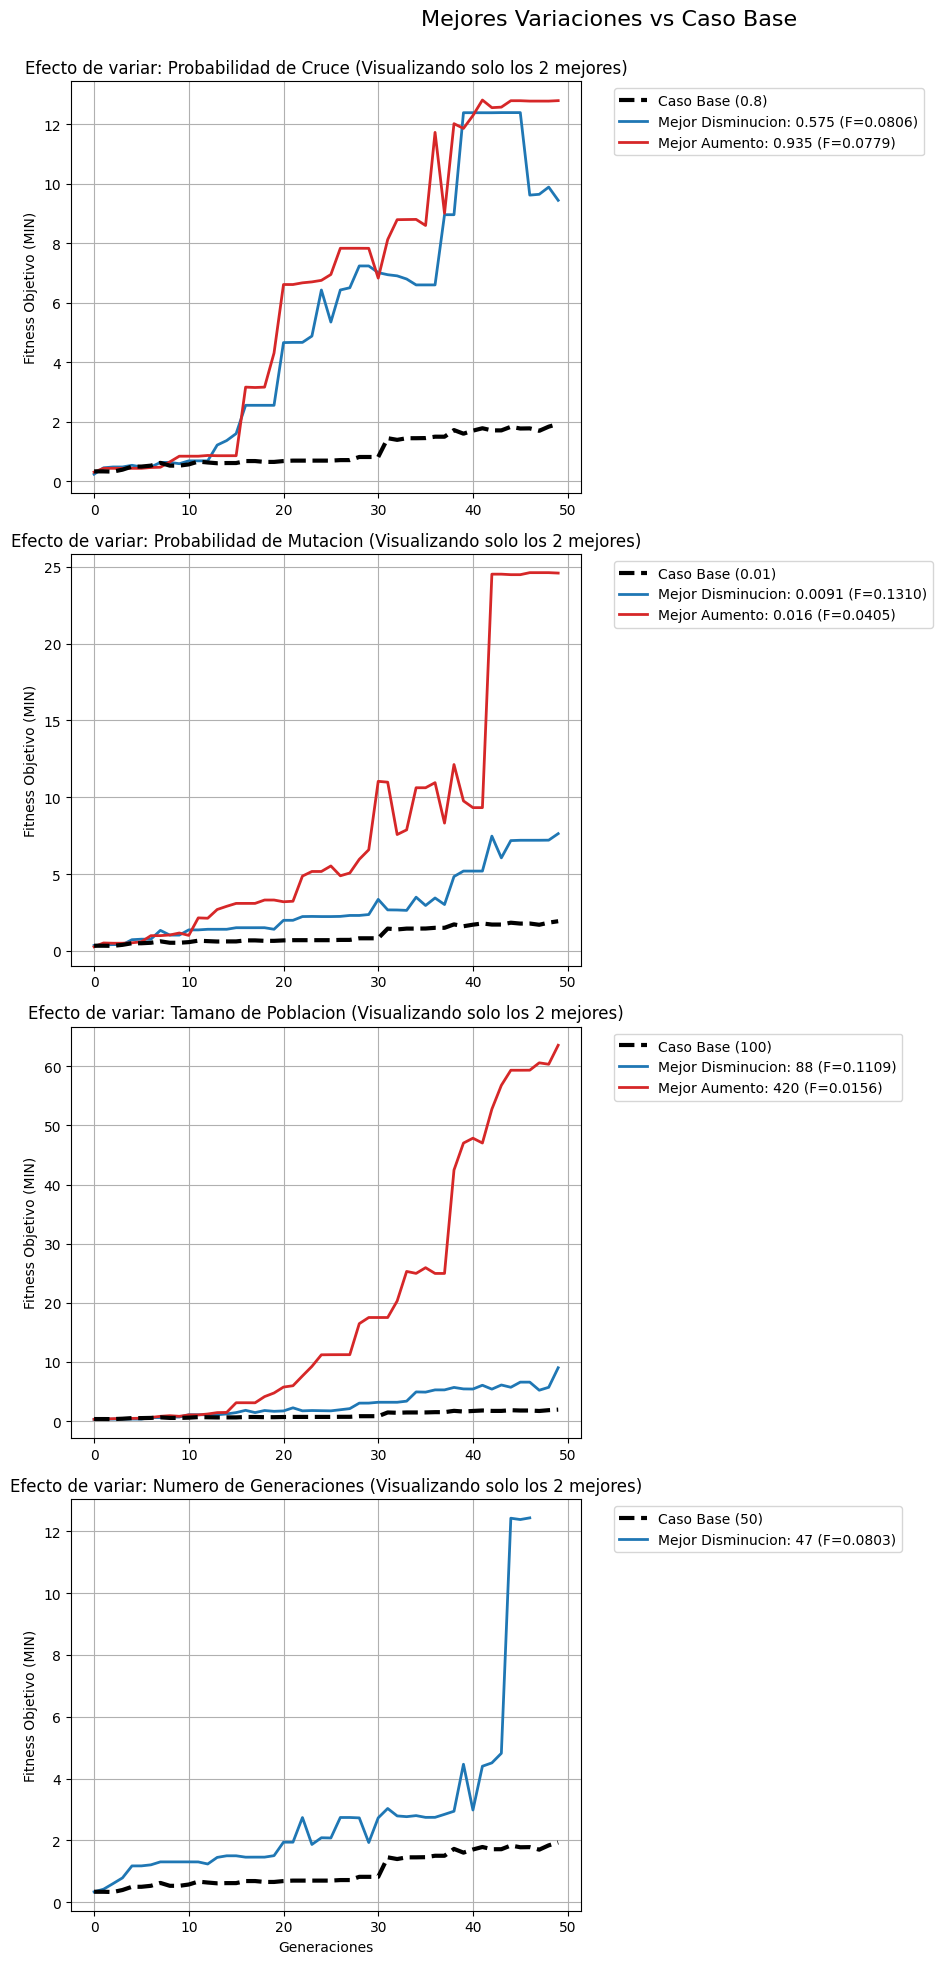


TABLA 2 EVALUACION ANTE LA VARIACION ESCALONADA


Parametro a Variar        | Valor Evaluado  | Mejor Individuo Alcanzado (F2 y Coords)

TODOS (Caso Base)         | Valores Base    | F(x)= 0.518045 en [X:0.02982394, Y:-0.00353747, Z:-0.01612224]
-------------------------------------------------------------------------------------
Numero de Generaciones    | 20              | F(x)= 0.74737 en [X:0.01233245, Y:-0.06125074, Z:0.00618516]
Numero de Generaciones    | 22              | F(x)= 0.35569 en [X:-0.00742894, Y:-0.00653970, Z:0.00175573]
Numero de Generaciones    | 23              | F(x)= 0.35253 en [X:0.00193514, Y:-0.01557348, Z:-0.00710205]
Numero de Generaciones    | 24              | F(x)= 0.65792 en [X:-0.01751782, Y:-0.00208023, Z:-0.05848547]
Numero de Generaciones    | 26              | F(x)= 1.52929 en [X:0.20755134, Y:0.08834342, Z:-0.13454514]
Numero de Generaciones    | 28              | F(x)= 1.92053 en [X:0.02695427, Y:-0.50960478, Z:-0.14877488]
Numero de Generacion

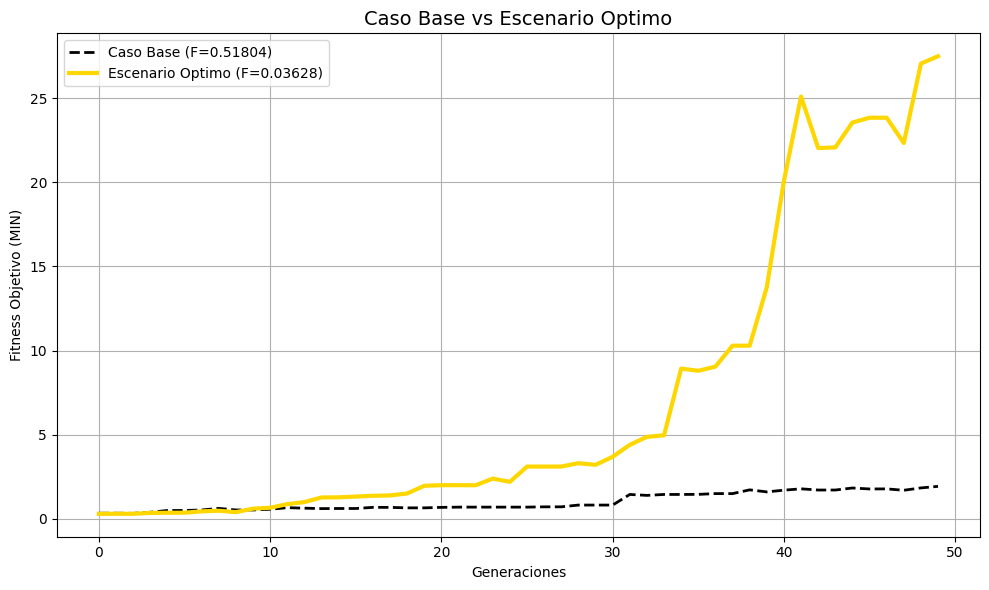

 TABLA 4: Escenario Optimo
Metrica                                | Valor Alcanzado
Mejor Resultado Global (Historico)     | F(x)= 0.036276 en [X:0.00000855, Y:-0.00003030, Z:-0.00023370]
Mejor F(x) Ultima Generacion           | F(x)= 0.036276 en [X:0.00000855, Y:-0.00003030, Z:-0.00023370]
¿Logro superar el resultado del Caso Base? -> SI


In [13]:

print("\nFASE 2.2: ANALISIS DE SENSIBILIDAD")
print("Funcion a evaluar: F2 (Obligatorio)")

fase_22 = "2.2"
parametros2 = configurar_sga(fase_22)

# Valores base dictados por la tarea
n_bits_x = parametros2['bits']['x']
n_bits_y = parametros2['bits']['y']
n_bits_z = parametros2['bits']['z']
base_n = parametros2['valores_base']['n_poblacion']
base_pc = parametros2['valores_base']['p_cruce']
base_pm = parametros2['valores_base']['p_mutacion']
base_gen = parametros2['valores_base']['epoch_max']
t_optimizacion = parametros2['t_optimizacion']

# Cantidad de pasos a evaluar por arriba y por abajo
n_pasos = 20

# CONFIGURADOR DE VARIACIONES
print("\nDefina los LIMITES MAXIMOS Y MINIMOS para el analisis de sensibilidad.")

inp = input(f"Prob. Cruce LIMITE SUPERIOR (>{base_pc}) [Enter para 0.95]: ")
pc_alta = float(inp) if inp != "" else 0.95

inp = input(f"Prob. Cruce LIMITE INFERIOR (<{base_pc}) [Enter para 0.50]: ")
pc_baja = float(inp) if inp != "" else 0.50

inp = input(f"Prob. Mutacion LIMITE SUPERIOR (>{base_pm}) [Enter para 0.05]: ")
pm_alta = float(inp) if inp != "" else 0.05

inp = input(f"Prob. Mutacion LIMITE INFERIOR (<{base_pm}) [Enter para 0.001]: ")
pm_baja = float(inp) if inp != "" else 0.001

inp = input(f"Tamano Poblacion LIMITE SUPERIOR (>{base_n}) [Enter para 200]: ")
n_alta = int(inp) if inp != "" else 200

inp = input(f"Tamano Poblacion LIMITE INFERIOR (<{base_n}) [Enter para 50]: ")
n_baja = int(inp) if inp != "" else 50

inp = input(f"Generaciones LIMITE SUPERIOR (>{base_gen}) [Enter para 100]: ")
gen_alta = int(inp) if inp != "" else 100

inp = input(f"Generaciones LIMITE INFERIOR (<{base_gen}) [Enter para 20]: ")
gen_baja = int(inp) if inp != "" else 20


# calcula los pasos (base - limite) / pasos
def generar_pasos(base, limite, pasos, es_entero=False):
    tamaño_paso = abs(base - limite) / pasos
    valores = []
    for i in range(1, pasos + 1):

        valor = base + (i * tamaño_paso) if limite > base else base - (i * tamaño_paso)

        if es_entero:
            valores.append(int(round(valor)))
        else:
            valores.append(round(valor, 6))
    return valores

# EJECUCION Y GENERACION DE GRAFICOS

print(f"\nEjecutando simulaciones ({n_pasos} pasos por arriba y {n_pasos} por abajo)...")

# Ejecutamos el caso base para comparar
hist_base, val_base, coord_base = ejecutar_evolucion_f2(base_n, base_gen, base_pc, base_pm, n_bits_x, n_bits_y, n_bits_z, t_optimizacion)

# Lista de variaciones (Arriba + Abajo) usando la funcion generar_pasos
pc_variaciones = generar_pasos(base_pc, pc_alta, n_pasos) + generar_pasos(base_pc, pc_baja, n_pasos)
pm_variaciones = generar_pasos(base_pm, pm_alta, n_pasos) + generar_pasos(base_pm, pm_baja, n_pasos)
n_variaciones = generar_pasos(base_n, n_alta, n_pasos, es_entero=True) + generar_pasos(base_n, n_baja, n_pasos, es_entero=True)
gen_variaciones = generar_pasos(base_gen, gen_alta, n_pasos, es_entero=True) + generar_pasos(base_gen, gen_baja, n_pasos, es_entero=True)

# diccionario de escenarios
escenarios = {
    "Probabilidad de Cruce": [
        (f"+{v}" if v > base_pc else f"{v}", v, base_n, base_gen, v, base_pm) for v in pc_variaciones
    ],
    "Probabilidad de Mutacion": [
        (f"+{v}" if v > base_pm else f"{v}", v, base_n, base_gen, base_pc, v) for v in pm_variaciones
    ],
    "Tamano de Poblacion": [
        (f"+{v}" if v > base_n else f"{v}", v, v, base_gen, base_pc, base_pm) for v in n_variaciones
    ],
    "Numero de Generaciones": [
        (f"+{v}" if v > base_gen else f"{v}", v, base_n, v, base_pc, base_pm) for v in gen_variaciones
    ]
}

tabla_2_resultados = []

tabla_mejores_absolutos = [] # Tabla para los campeones

# determina si un valor es mejor que otro
def es_mejor(val_nuevo, val_actual):
    if val_actual is None: return True
    return val_nuevo < val_actual if t_optimizacion == "MIN" else val_nuevo > val_actual

# figura con 4 subgraficos
fig, axs = plt.subplots(4, 1, figsize=(12, 20))
fig.suptitle(f"Mejores Variaciones vs Caso Base", fontsize=16)

idx_grafico = 0
for parametro, pruebas in escenarios.items():
    ax = axs[idx_grafico]

    # valor base correspondiente al parametro actual
    if parametro == "Probabilidad de Cruce": base_val = base_pc
    elif parametro == "Probabilidad de Mutacion": base_val = base_pm
    elif parametro == "Tamano de Poblacion": base_val = base_n
    else: base_val = base_gen

    # Graficamos siempre el caso base de referencia
    ax.plot(hist_base, label=f"Caso Base ({base_val})", color='black', linestyle='--', linewidth=3, zorder=10)

    ejecuciones = []

    # Correr todas las pruebas para este parámetro y guardar los datos
    for nombre_prueba, valor_evaluado, test_n, test_gen, test_pc, test_pm in pruebas:

        hist_test, val_test, coord_test = ejecutar_evolucion_f2(test_n, test_gen, test_pc, test_pm, n_bits_x, n_bits_y, n_bits_z, t_optimizacion)

        coords_str = f"X:{coord_test[0]:.8f}, Y:{coord_test[1]:.8f}, Z:{coord_test[2]:.8f}"

        ejecuciones.append({
            "valor_evaluado": valor_evaluado,
            "hist": hist_test,
            "val_test": val_test,
            "coords_str": coords_str
        })

        # Guardamos todo en la tabla general
        tabla_2_resultados.append({
            "parametro": parametro,
            "variacion": f"{valor_evaluado}",
            "mejor_valor": val_test,
            "coordenadas": coords_str
        })

    # Filtrar para buscar a los campeones de esta ronda
    pruebas_abajo = [e for e in ejecuciones if e["valor_evaluado"] < base_val]
    pruebas_arriba = [e for e in ejecuciones if e["valor_evaluado"] > base_val]

    mejor_abajo = None
    for e in pruebas_abajo:
        if es_mejor(e["val_test"], mejor_abajo["val_test"] if mejor_abajo else None):
            mejor_abajo = e

    mejor_arriba = None
    for e in pruebas_arriba:
        if es_mejor(e["val_test"], mejor_arriba["val_test"] if mejor_arriba else None):
            mejor_arriba = e

    mejor_absoluto = None
    for e in ejecuciones:
        if es_mejor(e["val_test"], mejor_absoluto["val_test"] if mejor_absoluto else None):
            mejor_absoluto = e

    # Graficar unicamente los campeones por arriba y por abajo
    if mejor_abajo:
        ax.plot(mejor_abajo["hist"], label=f"Mejor Disminucion: {mejor_abajo['valor_evaluado']} (F={mejor_abajo['val_test']:.4f})", color='#1f77b4', linewidth=2)
    if mejor_arriba:
        ax.plot(mejor_arriba["hist"], label=f"Mejor Aumento: {mejor_arriba['valor_evaluado']} (F={mejor_arriba['val_test']:.4f})", color='#d62728', linewidth=2)

    # Guardar el mejor resultado para la nueva tabla
    if mejor_absoluto:
        tabla_mejores_absolutos.append({
            "parametro": parametro,
            "variacion": mejor_absoluto["valor_evaluado"],
            "mejor_valor": mejor_absoluto["val_test"],
            "coordenadas": mejor_absoluto["coords_str"]
        })

    ax.set_title(f"Efecto de variar: {parametro} (Visualizando solo los 2 mejores)")
    ax.set_ylabel(f"Fitness Objetivo ({t_optimizacion})")
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    ax.grid(True)
    idx_grafico += 1

plt.xlabel("Generaciones")
plt.tight_layout(rect=[0, 0, 0.80, 0.98])
plt.show()




#  TABLA 2
print("\nTABLA 2 EVALUACION ANTE LA VARIACION ESCALONADA\n")

print(f"\n{'Parametro a Variar':<25} | {'Valor Evaluado':<15} | {'Mejor Individuo Alcanzado (F2 y Coords)'}\n")

info_base = f"F(x)= {val_base:.6f} en [X:{coord_base[0]:.8f}, Y:{coord_base[1]:.8f}, Z:{coord_base[2]:.8f}]"
print(f"{'TODOS (Caso Base)':<25} | {'Valores Base':<15} | {info_base}")
print("-" * 85)

# Ordenamos los resultados para que se muestren de menor a mayor valor evaluado
tabla_2_ordenada = sorted(tabla_2_resultados, key=lambda x: (x['parametro'], float(x['variacion'])))
for res in tabla_2_ordenada:
    info_individuo = f"F(x)= {res['mejor_valor']:.5f} en [{res['coordenadas']}]"
    print(f"{res['parametro']:<25} | {res['variacion']:<15} | {info_individuo}")
print("-" * 85)

# TABLA 3 DE CAMPEONES
print("\nTABLA 3 LOS MEJORES PARAMETROS\n")
print(f"{'\nParametro a Variar':<25} | {'Mejor Ajuste':<15} | {'Mejor Individuo Alcanzado (F2 y Coords)'}\n")

for res in tabla_mejores_absolutos:
    info_individuo = f"F(x)= {res['mejor_valor']:.5f} en [{res['coordenadas']}]"
    # Añadimos un pequeño indicador visual para ver si mejoró al caso base
    print(f"{res['parametro']:<25} | {res['variacion']:<15} | {info_individuo}")
print("*" * 85)


# EJECUCION COMBINANDO LOS MEJORES PARAMETROS
print("\nEVALUANDO EL ESCENARIO CON LOS CAMPEONES\n")

# Extraer los mejores valores descubiertos en el analisis de sensibilidad
mejor_pc_descubierto = base_pc
mejor_pm_descubierto = base_pm
mejor_n_descubierto = base_n
mejor_gen_descubierto = base_gen

for res in tabla_mejores_absolutos:
    if res['parametro'] == "Probabilidad de Cruce":
        mejor_pc_descubierto = float(res['variacion'])
    elif res['parametro'] == "Probabilidad de Mutacion":
        mejor_pm_descubierto = float(res['variacion'])
    elif res['parametro'] == "Tamano de Poblacion":
        mejor_n_descubierto = int(res['variacion'])
    elif res['parametro'] == "Numero de Generaciones":
        mejor_gen_descubierto = int(res['variacion'])

print(f"Configuracion del Escenario con Campeones:")
print(f"* Poblacion: {mejor_n_descubierto}")
print(f"* Generaciones: {mejor_gen_descubierto}")
print(f"* Prob. Cruce: {mejor_pc_descubierto}")
print(f"* Prob. Mutacion: {mejor_pm_descubierto}")
print("\nEjecutando escenario...")

# Ejecutar la evolucion con la combinación ganadora
hist_super, val_super, coord_super = ejecutar_evolucion_f2(
    mejor_n_descubierto, mejor_gen_descubierto,
    mejor_pc_descubierto, mejor_pm_descubierto,
    n_bits_x, n_bits_y, n_bits_z, t_optimizacion
)

# Graficar Caso Base vs Escenario optimo
plt.figure(figsize=(10, 6))
plt.title("Caso Base vs Escenario Optimo", fontsize=14)

# Graficar base
plt.plot(hist_base, label=f"Caso Base (F={val_base:.5f})", color='black', linestyle='--', linewidth=2)

# Graficar Escenario optimo
plt.plot(hist_super, label=f"Escenario Optimo (F={val_super:.5f})", color='gold', linewidth=3)

plt.xlabel("Generaciones")
plt.ylabel(f"Fitness Objetivo ({t_optimizacion})")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# Preparar datos para la Tabla 4
coords_super_str = f"X:{coord_super[0]:.8f}, Y:{coord_super[1]:.8f}, Z:{coord_super[2]:.8f}"

# El historial guarda el fitness interno de la ruleta
# Vamos a convertir ese fitness de vuelta a F(x) real usando el despeje matemático.
ultimo_fitness_interno = hist_super[-1]
if t_optimizacion == "MIN":
    # Despejamos F(x) de la formula: fitness = 1 / (F(x) + 0.0001)
    f_x_ultima = (1.0 / ultimo_fitness_interno) - 0.0001
else:
    # En MAX, el fitness es directamente F(x)
    f_x_ultima = ultimo_fitness_interno

if abs(val_super - f_x_ultima) < 1e-7:
    coords_ultima_str = coords_super_str
else:
    coords_ultima_str = "Coordenadas no estan en historial"

# Evaluamos si el Escenario optimo supera al Caso Base
mejoro_base = "SI" if es_mejor(val_super, val_base) else "NO"

# TABLA 4
print(" TABLA 4: Escenario Optimo")
print(f"{'Metrica':<38} | {'Valor Alcanzado'}")
print(f"{'Mejor Resultado Global (Historico)':<38} | F(x)= {val_super:.6f} en [{coords_super_str}]")
print(f"{'Mejor F(x) Ultima Generacion':<38} | F(x)= {f_x_ultima:.6f} en [{coords_ultima_str}]")
print(f"¿Logro superar el resultado del Caso Base? -> {mejoro_base}")
